# Project 19: Data Quality Audit & Anti-Bypass Template
Data simulasi. Notebook membaca CSV hasil pipeline (`results/`); angka tidak dihitung ulang di sini.

In [1]:
from pathlib import Path
import pandas as pd
R2 = Path('..') / '2-analysis'
R1 = Path('..') / '1-data-preparation'
rd = lambda n, d=R2: pd.read_csv(d / n)


## Q1 sampai Q3: error per kategori, kolom, aturan

In [2]:
print('audit_category.csv'); display(rd('audit_category.csv'))

audit_category.csv


,version,category,pelanggaran,entri_terdampak,entri,per_1000,ci_low,ci_high
0,before,salah isi,64,64,1839,34.801523,26.801413,44.440767
1,before,dilewati,36,36,1839,19.575856,13.710689,27.101237
2,before,bypass,23,23,1839,12.506797,7.928237,18.766337
3,before,semua,123,121,1839,66.884176,55.587290,79.802295
4,after,salah isi,3,3,1822,1.646542,0.339557,4.811895
5,after,dilewati,0,0,1822,0.000000,0.000000,2.024632
6,after,bypass,0,0,1822,0.000000,0.000000,2.024632
7,after,semua,3,3,1822,1.646542,0.339557,4.811895


In [3]:
print('audit_column.csv'); display(rd('audit_column.csv'))

audit_column.csv


,version,column,pelanggaran,per_1000,share
0,after,Batch,2,1.097695,0.666667
1,after,Sisa Awal,1,0.548847,0.333333
2,before,Sisa,23,12.506797,0.186992
3,before,Batch,19,10.331702,0.154472
4,before,Model,17,9.244154,0.138211
5,before,Stasiun Asal,16,8.700381,0.130081
6,before,Qty OK,15,8.156607,0.121951
7,before,Qty Scrap,15,8.156607,0.121951
8,before,Qty Diterima,8,4.350190,0.065041
9,before,Sisa Awal,6,3.262643,0.048780


In [4]:
print('audit_rule_counts.csv'); display(rd('audit_rule_counts.csv'))

audit_rule_counts.csv


,version,rule_id,category,pelanggaran,entri,per_1000,ci_low,ci_high
0,before,R01,salah isi,6,1839,3.262643,1.197332,7.101400
1,before,R02,salah isi,15,1839,8.156607,4.565191,13.453083
2,before,R03,dilewati,36,1839,19.575856,13.710689,27.101237
3,before,R04,salah isi,18,1839,9.787928,5.800947,15.469146
4,before,R05,bypass,23,1839,12.506797,7.928237,18.766337
5,before,R06,salah isi,19,1839,10.331702,6.220360,16.134232
6,before,R07,salah isi,6,1839,3.262643,1.197332,7.101400
7,after,R01,salah isi,0,1822,0.000000,0.000000,2.024632
8,after,R02,salah isi,0,1822,0.000000,0.000000,2.024632
9,after,R03,dilewati,0,1822,0.000000,0.000000,2.024632


## Q4 dan Q5: pola per shift, model, minggu, volume

In [5]:
print('patterns.csv'); display(rd('patterns.csv'))

patterns.csv


,version,faktor,level,entri,bermasalah,proporsi,ci_low,ci_high
0,before,shift,(kosong),4,4,1.000000,0.510109,1.000000
1,before,shift,Shift 1,917,60,0.065431,0.051169,0.083318
2,before,shift,Shift 2,918,57,0.062092,0.048232,0.079601
3,before,model,(kosong),6,6,1.000000,0.609666,1.000000
4,before,model,PCB-A1,445,27,0.060674,0.042031,0.086838
5,before,model,PCB-A2,465,29,0.062366,0.043771,0.088132
6,before,model,PCB-B1,462,31,0.067100,0.047671,0.093668
7,before,model,PCB-B2,461,28,0.060738,0.042353,0.086382
8,before,minggu,hari lain,1443,100,0.069300,0.057308,0.083580
9,before,minggu,minggu terakhir bulan,396,21,0.053030,0.034944,0.079706


In [6]:
print('patterns_tests.csv'); display(rd('patterns_tests.csv'))

patterns_tests.csv


,version,faktor,chi2,dof,p,kelompok,bermasalah_total,p_holm,signifikan
0,before,shift,0.038882,1,0.843683,2,117,1,0
1,before,model,0.214167,3,0.975270,4,115,1,0
2,before,minggu,1.086527,1,0.297242,2,121,1,0
3,before,volume harian,2.453187,2,0.293290,3,121,1,0
4,after,shift,0.000000,1,1.000000,2,3,1,0
5,after,model,3.764114,3,0.288088,4,3,1,0
6,after,minggu,0.000000,1,1.000000,2,3,1,0
7,after,volume harian,0.001392,2,0.999304,3,3,1,0


In [7]:
print('patterns_r03.csv'); display(rd('patterns_r03.csv'))

patterns_r03.csv


,version,faktor,level,entri,entri_R03,proporsi
0,before,shift,(kosong),4,4,1.000000
1,before,shift,Shift 1,917,15,0.016358
2,before,shift,Shift 2,918,17,0.018519
3,before,minggu,hari lain,1443,30,0.020790
4,before,minggu,minggu terakhir bulan,396,6,0.015152


## Q6 dan Q7: rumus ditimpa angka ketikan

In [8]:
print('formula_hardcode.csv'); display(rd('formula_hardcode.csv'))

formula_hardcode.csv


,version,workbook,sheet,column,sel_rumus,angka_ketikan,persen_ketikan,ci_low,ci_high
0,after,log_template,Log,Sisa,1822,0,0.000000,0.000000,0.002104
1,before,log_lama,Log,Sisa,1839,23,0.012507,0.008348,0.018698


In [9]:
print('formula_diff_summary.csv'); display(rd('formula_diff_summary.csv'))

formula_diff_summary.csv


,version,sel_ketikan,sama_dengan_rumus,berbeda,tak_terhitung,rata_selisih_abs,median_selisih_abs,maks_selisih_abs,total_selisih_bersih,total_selisih_abs
0,before,23,9,13,1,3.3182,2.0,26.0,-35.0,73.0


## Q8 dan Q9: rekonsiliasi rekap dan carry-over

In [10]:
print('recap_reconcile.csv'); display(rd('recap_reconcile.csv'))

recap_reconcile.csv


,version,bulan,diterima_mentah,diterima_koreksi,ok_mentah,ok_koreksi,scrap_mentah,scrap_koreksi,sisa_mentah,sisa_koreksi,entri_mentah,entri_koreksi,selisih_diterima,persen_selisih_diterima,selisih_ok,persen_selisih_ok,selisih_scrap,persen_selisih_scrap,selisih_sisa,persen_selisih_sisa
0,after,2026-07,44509.0,44419.0,41925.0,41850.0,2330.0,2328.0,15326.0,15291.0,645,644,90.0,0.002026,75.0,0.001792,2.0,0.000859,35.0,0.002289
1,after,2026-08,41399.0,41399.0,39238.0,39238.0,2220.0,2220.0,14688.0,14688.0,588,588,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000
2,after,2026-09,40420.0,40392.0,38232.0,38197.0,2158.0,2158.0,13898.0,13881.0,589,588,28.0,0.000693,35.0,0.000916,0.0,0.000000,17.0,0.001225
3,before,2026-07,45250.0,44932.0,42510.0,42207.0,2406.0,2410.0,15486.0,15334.0,649,644,318.0,0.007077,303.0,0.007179,-4.0,-0.001660,152.0,0.009913
4,before,2026-08,42274.0,41710.0,40479.0,39904.0,2179.0,2193.0,14009.5,13810.0,596,588,564.0,0.013522,575.0,0.014410,-14.0,-0.006384,199.5,0.014446
5,before,2026-09,42075.0,41749.0,39586.0,39291.0,2196.0,2189.0,14894.5,14770.0,594,588,326.0,0.007809,295.0,0.007508,7.0,0.003198,124.5,0.008429


In [11]:
print('recap_reconcile_sensitivity.csv'); display(rd('recap_reconcile_sensitivity.csv'))

recap_reconcile_sensitivity.csv


,version,bulan,diterima_mentah,diterima_koreksi,ok_mentah,ok_koreksi,scrap_mentah,scrap_koreksi,sisa_mentah,sisa_koreksi,entri_mentah,entri_koreksi,selisih_diterima,persen_selisih_diterima,selisih_ok,persen_selisih_ok,selisih_scrap,persen_selisih_scrap,selisih_sisa,persen_selisih_sisa
0,after,2026-07,44509.0,44419.0,41925.0,41850.0,2330.0,2328.0,15326.0,15291.0,645,644,90.0,0.002026,75.0,0.001792,2.0,0.000859,35.0,0.002289
1,after,2026-08,41399.0,41399.0,39238.0,39238.0,2220.0,2220.0,14688.0,14688.0,588,588,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000
2,after,2026-09,40420.0,40392.0,38232.0,38197.0,2158.0,2158.0,13898.0,13881.0,589,588,28.0,0.000693,35.0,0.000916,0.0,0.000000,17.0,0.001225
3,before,2026-07,45250.0,44932.0,42510.0,42207.0,2406.0,2410.0,15486.0,15334.0,649,644,318.0,0.007077,303.0,0.007179,-4.0,-0.001660,152.0,0.009913
4,before,2026-08,42274.0,41710.0,40479.0,39904.0,2179.0,2196.0,14009.5,13807.0,596,588,564.0,0.013522,575.0,0.014410,-17.0,-0.007741,202.5,0.014666
5,before,2026-09,42075.0,41749.0,39586.0,39291.0,2196.0,2190.0,14894.5,14769.0,594,588,326.0,0.007809,295.0,0.007508,6.0,0.002740,125.5,0.008498


In [12]:
print('carryover_summary.csv'); display(rd('carryover_summary.csv'))

carryover_summary.csv


,version,pasangan,cocok,tidak_cocok,persen_cocok
0,after,24,23,1,0.958333
1,before,23,17,6,0.739130


## Q10, Q11, Q14: before-after, error tersisa, jam koreksi (estimated)

In [13]:
print('before_after.csv'); display(rd('before_after.csv'))

before_after.csv


,entri_before,entri_after,pelanggaran_before,pelanggaran_after,error_per_1000_before,error_per_1000_after,penurunan,penurunan_ci_low,penurunan_ci_high,target_penurunan,...,tercapai_ci_low,entri_bermasalah_before,entri_bermasalah_after,proporsi_before,proporsi_after,prop_before_ci_low,prop_before_ci_high,prop_after_ci_low,prop_after_ci_high,p_fisher
0,1839,1822,123,3,66.884176,1.646542,0.975382,0.94286,1,0.7,...,1,121,3,0.065797,0.001647,0.055346,0.078058,0.00056,0.00483,4.936634e-33


In [14]:
print('before_after_category.csv'); display(rd('before_after_category.csv'))

before_after_category.csv


,category,before,after,per_1000_before,per_1000_after,penurunan
0,salah isi,64,3,34.801523,1.646542,0.952688
1,dilewati,36,0,19.575856,0.000000,1.000000
2,bypass,23,0,12.506797,0.000000,1.000000


In [15]:
print('remaining_by_rule.csv'); display(rd('remaining_by_rule.csv'))

remaining_by_rule.csv


,rule_id,deskripsi,kategori,before,after
0,R01,Qty OK + Qty Scrap tidak boleh melebihi stok t...,salah isi,6,0
1,R02,Semua qty bilangan bulat >= 0,salah isi,15,0
2,R03,Kolom wajib tidak boleh kosong,dilewati,36,0
3,R04,"Shift, model, dan stasiun asal harus dari daft...",salah isi,18,0
4,R05,Sel Sisa harus berisi rumus,bypass,23,0
5,R06,"Tidak boleh ada dua baris dengan tanggal, shif...",salah isi,19,2
6,R07,Sisa awal bulan sama dengan sisa akhir bulan s...,salah isi,6,1


In [16]:
print('hours_saved.csv'); display(rd('hours_saved.csv'))

hours_saved.csv


,volume_entri_per_bulan,menit_per_error,error_tercegah_per_bulan,jam_hemat_per_bulan,ci_low,ci_high,label
0,610.166667,10,39.80583,6.634305,5.417719,7.850878,estimated


In [17]:
print('kpi.csv'); display(rd('kpi.csv'))

kpi.csv


,version,error_per_1000,salah_isi_per_1000,dilewati_per_1000,bypass_per_1000,first_time_right,selisih_rekap_ok_persen,selisih_rekap_sisa_persen
0,before,66.884176,34.801523,19.575856,12.506797,0.934203,0.009662,0.010839
1,after,1.646542,1.646542,0.000000,0.000000,0.998353,0.000922,0.001186


## Q12: inventaris kolom

In [18]:
print('column_inventory_summary.csv'); display(rd('column_inventory_summary.csv'))

column_inventory_summary.csv


,versi,peran,jumlah_kolom
0,log lama,input operator,9
1,log lama,rumus (seharusnya),1
2,template,input operator,7
3,template,rumus terkunci,4


## Q13: recall dan precision terhadap ground truth

In [19]:
print('ground_truth_recall.csv'); display(rd('ground_truth_recall.csv'))

ground_truth_recall.csv


,version,rule_id,ditanam,terdeteksi,tp,fn,fp,recall,recall_ci_low,recall_ci_high,precision,pr_ci_low,pr_ci_high,alarm_palsu
0,before,R01,42,6,6,36,0,0.142857,0.067159,0.278414,1.000000,0.609657,1.000000,0.000000
1,before,R02,15,15,15,0,0,1.000000,0.796111,1.000000,1.000000,0.796111,1.000000,0.000000
2,before,R03,36,36,36,0,0,1.000000,0.903578,1.000000,1.000000,0.903578,1.000000,0.000000
3,before,R04,18,18,18,0,0,1.000000,0.824115,1.000000,1.000000,0.824115,1.000000,0.000000
4,before,R05,23,23,23,0,0,1.000000,0.856879,1.000000,1.000000,0.856879,1.000000,0.000000
5,before,R06,19,19,19,0,0,1.000000,0.831816,1.000000,1.000000,0.831816,1.000000,0.000000
6,before,R07,8,6,5,3,1,0.625000,0.305738,0.863158,0.833333,0.436491,0.969947,0.166667
7,after,R01,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,after,R02,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,after,R03,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
print('ground_truth_r01_sensitivity.csv'); display(rd('ground_truth_r01_sensitivity.csv'))

ground_truth_r01_sensitivity.csv


,version,ditanam,terdeteksi,tp,recall,precision,definisi
0,before,42,6,6,0.142857,1.000000,stok tersedia (dasar)
1,after,0,0,0,NaN,NaN,stok tersedia (dasar)
2,before,42,910,42,1.000000,0.046154,qty diterima saja (rancangan literal)
3,after,0,886,0,NaN,0.000000,qty diterima saja (rancangan literal)


In [21]:
print('ground_truth_r07.csv'); display(rd('ground_truth_r07.csv'))

ground_truth_r07.csv


,version,ditanam,tak_dapat_dideteksi,dapat_dideteksi,terdeteksi,recall_dapat_dideteksi
0,after,2,1,1,1,1.000000
1,before,8,2,6,5,0.833333


In [22]:
print('ground_truth_overall.csv'); display(rd('ground_truth_overall.csv'))

ground_truth_overall.csv


,version,entri,entri_ditanam,entri_bertanda,tp,recall_entri,precision_entri,alarm_palsu_persen_entri_bersih,tercapai_recall,tercapai_alarm
0,before,1839,155,121,120,0.774194,0.991736,0.000594,0,1
1,after,1822,4,3,3,0.750000,1.000000,0.000000,0,1


In [23]:
print('design_facts.csv'); display(rd('design_facts.csv'))

design_facts.csv


,fakta,rancangan,ukuran,nilai,n,k,ukuran2,nilai2,nilai3
0,1,3% entri OK + scrap melebihi qty diterima,"entri R01 proporsi entri (definisi dasar, stok...",0.003263,1839,6,definisi literal (qty diterima saja),0.494834,NaN
1,2,"2% sel wajib kosong, terpusat shift malam dan ...",entri R03 proporsi entri,0.019576,1839,36,p-value R03 Shift 2 vs Shift 1 | minggu terakh...,0.743849,0.473102
2,3,"1,5% sel Sisa ditimpa angka, terpusat bulan ke-3",entri R05 proporsi entri,0.012507,1839,23,porsi R05 di bulan ke-3 | p-value binomial vs ...,0.391304,0.506706
3,4,carry-over bulanan putus,pasangan bulan dengan Sisa Awal tidak sama / p...,0.260870,23,6,NaN,NaN,NaN
4,5,2% sampai 3% data kotor lain (format dan dupli...,"entri R02, R04, atau R06 proporsi entri",0.028276,1839,52,NaN,NaN,NaN


## Cek silang dan uji template

In [24]:
print('crosscheck.csv'); display(rd('crosscheck.csv'))

crosscheck.csv


,cek,version,item,nilai_a,nilai_b,cocok
0,pandas vs loop Python,before,R01,6.0,6.0,1
1,pandas vs loop Python,before,R02,15.0,15.0,1
2,pandas vs loop Python,before,R03,36.0,36.0,1
3,pandas vs loop Python,before,R04,18.0,18.0,1
4,pandas vs loop Python,before,R05,23.0,23.0,1
5,pandas vs loop Python,before,R06,19.0,19.0,1
6,pandas vs loop Python,after,R01,0.0,0.0,1
7,pandas vs loop Python,after,R02,0.0,0.0,1
8,pandas vs loop Python,after,R03,0.0,0.0,1
9,pandas vs loop Python,after,R04,0.0,0.0,1


In [25]:
print('template_test.csv'); display(rd('template_test.csv'))

template_test.csv


,cek,dibandingkan,cocok
0,kolom batch,1822,1822
1,kolom sisa_awal,1822,1822
2,kolom sisa,1822,1822
3,kolom cek,1822,1822
4,Rekap entri,12,12
5,Rekap diterima,12,12
6,Rekap ok,12,12
7,Rekap scrap,12,12
8,Rekap bertanda,12,12
9,ABNORMAL == R01 pada data uji,1822,1821


Pareto pelanggaran per aturan (log lama)

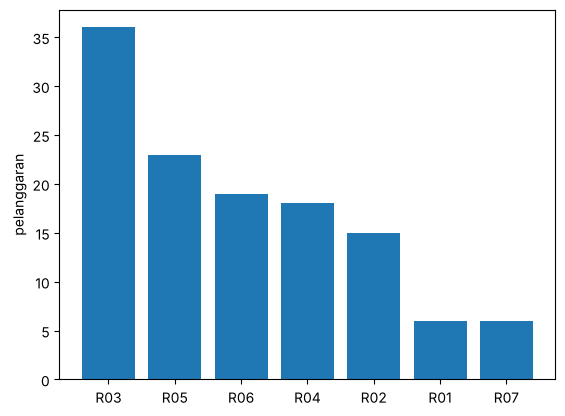

In [26]:
import matplotlib.pyplot as plt
d = rd('audit_rule_counts.csv'); d = d[d.version == 'before'].sort_values('pelanggaran', ascending=False)
plt.bar(d.rule_id, d.pelanggaran); plt.ylabel('pelanggaran'); plt.show()